# Exercise 5: copy/compute overlap and tail latency

## Question

Can a GPU beamforming pipeline sustain a stated input rate, and what happens to frame latency, queueing, and drops as the input rate approaches or exceeds service capacity?

This notebook replays measured PyMUST rotating-disk phantom data. It is a controlled replay experiment, not a live scanner feed. The RF-to-IQ conversion and geometry setup happen once before timing. Each replay frame is one receive acquisition processed by Mach; the GPU accumulates its power contribution and copies the final map to the host once per trial.


## What the two paths measure

| Path | Per-frame data movement | Scheduling | Purpose |
|---|---|---|---|
| Serialized | pinned host buffer → device frame buffer | wait for each copy, beamform, and power update to finish before accepting the next frame | baseline with transfer and compute serialized |
| Overlapped | pinned host buffer → one of two device frame buffers | copy stream feeds a compute stream; events protect each buffer while the GPU is using it | test whether the copy of a later frame can overlap beamforming of the current frame |

The Cython producer is used throughout the main rate sweep and the batching follow-up. It waits against absolute monotonic deadlines outside the GIL, then briefly reacquires the GIL to enqueue each arrival. The bounded queue holds at most eight waiting frames and drops the newest arrival when full. The overlap path has two frames in flight at most.

The report separates requested rate from actual producer timing. It records producer lateness, queue wait, host-observed frame latency, H2D and GPU event durations, deadline misses, queue depth, and drops. Failure bars divide dropped arrivals and accepted-late completions by all offered frames; the unfilled share is on-time completions. The deadline is one requested input period after each scheduled arrival. GPU event timings exclude producer and host scheduling time.

These are replayed stored frames with repeated content; they do not represent live acquisition timing or independent biological data. Cython reduces Python scheduling interference, while Mach's per-frame beamform launches and the small single-acquisition payload remain part of this experiment. Use Nsight Systems to check that the CUDA copy and compute lanes overlap before describing a measured benefit as actual GPU overlap.


In [76]:
from pathlib import Path
import os
import subprocess
import sys

CYCLES_PER_TRIAL = 256
MAIN_PRODUCER_KIND = "cython"
INPUT_RATES_HZ = (200, 500, 600, 700, 800, 900, 1_000, 1_500, 2_000, 3_000, 4_500, 6_000, 10_000)
QUEUE_CAPACITY = 8
REPLAYED_PRF_HZ = 10_000
POLL_INTERVAL_S = 0.0001
GRID_SIZE = 251

_candidates = [Path("/content/realtime-beamforming-lab"), Path.cwd(), *Path.cwd().resolve().parents]
ROOT = next((p.resolve() for p in _candidates if (p / "pyproject.toml").is_file()), Path.cwd().resolve())
RESULTS_DIR = ROOT / "results"
ARTIFACTS_DIR = ROOT / "artifacts"
RESULTS_DIR.mkdir(parents=True, exist_ok=True)
ARTIFACTS_DIR.mkdir(parents=True, exist_ok=True)
sys.path.insert(0, str(ROOT / "src"))

print("Repository:", ROOT)
print("Cycles per trial:", CYCLES_PER_TRIAL)
print("Main sweep producer:", MAIN_PRODUCER_KIND)
print("Offered rates (Hz):", INPUT_RATES_HZ)
print("Queue capacity:", QUEUE_CAPACITY)


Repository: /content/realtime-beamforming-lab
Cycles per trial: 256
Main sweep producer: cython
Offered rates (Hz): (200, 500, 600, 700, 800, 900, 1000, 1500, 2000, 3000, 4500, 6000, 10000)
Queue capacity: 8


### Install the Colab dependencies

Run this on the connected Colab T4 runtime. If pip requests a kernel restart, restart before continuing. The local lab source is imported from `src/` in the setup cell above.


In [48]:
%pip uninstall -y cupy-cuda12x cupy-cuda13x
%pip install --no-cache-dir "mach-beamform[examples,uff,vis]>=0.2.1,<0.3.0" "cupy-cuda13x>=13.0" "pymust>=0.1.9" "psutil>=5.9" "matplotlib>=3.9" "Cython>=3.0,<4"


Found existing installation: cupy-cuda13x 14.2.0
Uninstalling cupy-cuda13x-14.2.0:
  Successfully uninstalled cupy-cuda13x-14.2.0
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 69.0/69.0 MB 74.0 MB/s  0:00:00 eta 0:00:01


In [49]:
import importlib.metadata as package_metadata
import json
import platform
import time

import cupy as cp
import numpy as np
import psutil

if cp.cuda.runtime.getDeviceCount() < 1:
    raise RuntimeError("No CUDA device found. Connect this notebook to the Colab T4 runtime.")

_device_name = cp.cuda.runtime.getDeviceProperties(cp.cuda.Device().id)["name"]
if isinstance(_device_name, bytes):
    _device_name = _device_name.decode(errors="replace")
_git = subprocess.run(["git", "-C", str(ROOT), "rev-parse", "HEAD"], text=True, capture_output=True)
_versions = {}
for _name in ("mach-beamform", "cupy-cuda13x", "PyMUST", "numpy"):
    try:
        _versions[_name] = package_metadata.version(_name)
    except package_metadata.PackageNotFoundError:
        _versions[_name] = "not installed"

runtime_metadata = {
    "device": str(_device_name),
    "python": platform.python_version(),
    "platform": platform.platform(),
    "cpu_logical_count": os.cpu_count(),
    "memory_total_bytes": psutil.virtual_memory().total,
    "git_revision": _git.stdout.strip() if _git.returncode == 0 else None,
    "versions": _versions,
}
print(json.dumps(runtime_metadata, indent=2))
subprocess.run(["nvidia-smi"], check=False)


{
  "device": "Tesla T4",
  "python": "3.13.16",
  "platform": "Linux-6.6.159+-x86_64-with-glibc2.39",
  "cpu_logical_count": 2,
  "memory_total_bytes": 13605818368,
  "git_revision": "a8fcf90ae60592982808b257584404c5b40cbe39",
  "versions": {
    "mach-beamform": "0.2.1",
    "cupy-cuda13x": "14.2.0",
    "PyMUST": "0.1.9",
    "numpy": "2.4.6"
  }
}


CompletedProcess(args=['nvidia-smi'], returncode=0)

## Load the measured replay source

The source helper downloads/caches the PyMUST rotating-disk phantom, converts its RF to complex IQ once, and prepares the scan geometry. Those steps are outside all streaming timings. The per-frame transfer uses complex64 IQ, matching the existing Mach workload. The nominal source PRF is 10 kHz; the recorded file itself does not contain live timestamps, so arrivals below are generated by this notebook.


In [50]:
from beamforming_lab.beamformer import prepare_geometry, run_ensemble
from beamforming_lab.workload import load_pymust_doppler_workload

workload = load_pymust_doppler_workload(grid_size=GRID_SIZE)
geometry = prepare_geometry(workload, "cupy")
channel_data = workload.iq_elements_samples_frames
frame_count = int(channel_data.shape[2])
frame_shape = (int(channel_data.shape[0]), int(channel_data.shape[1]), 1)
frame_bytes = int(np.prod(frame_shape) * np.dtype(np.complex64).itemsize)
replay_frames = frame_count * CYCLES_PER_TRIAL

print("Dataset:", workload.data_provenance["dataset_id"])
print("Recording note:", workload.data_provenance["recording"])
print("IQ shape (elements, samples, frames):", channel_data.shape)
print("IQ dtype:", channel_data.dtype)
print(f"One replay frame: {frame_bytes:,} bytes ({frame_bytes / 2**20:.3f} MiB)")
print("Frames per trial:", replay_frames)
print(f"Nominal {REPLAYED_PRF_HZ:,} Hz period: {1e3 / REPLAYED_PRF_HZ:.3f} ms")
print(f"RF-to-IQ setup time (excluded): {workload.rf_to_iq_ms:.2f} ms")
print(f"Geometry upload time (excluded): {geometry.geometry_upload_ms:.2f} ms")


Dataset: PyMUST example PWI_disk.mat
Recording note: Ultrasound RF from a tissue-mimicking phantom with a rotating disk; not a brain or fUSI recording.
IQ shape (elements, samples, frames): (128, 334, 32)
IQ dtype: complex64
One replay frame: 342,016 bytes (0.326 MiB)
Frames per trial: 8192
Nominal 10,000 Hz period: 0.100 ms
RF-to-IQ setup time (excluded): 252.53 ms
Geometry upload time (excluded): 0.59 ms


## Replay implementation

The main source thread is a Cython producer. It schedules each arrival against an absolute `CLOCK_MONOTONIC` deadline with `clock_nanosleep` inside a `nogil` section, then reacquires the GIL briefly to enqueue a timestamp and frame index. The extension is built before any timed trials. All measured paths use this Cython producer and the same drop-newest policy and eight-frame waiting queue.

The serialized path waits for each H2D event before submitting compute, then waits for each frame's GPU work to complete. The overlap path queues H2D on a copy stream and makes the compute stream wait on a CUDA event; two pinned host and device slots prevent a frame buffer from being overwritten while the GPU is using it. Mach beamforming plus the GPU-side power reduction are included in each compute event. Geometry stays resident, and no frame-level D2H occurs. The stream and event calls follow CuPy's [stream](https://docs.cupy.dev/en/stable/reference/generated/cupy.cuda.Stream.html) and [`memcpyAsync`](https://docs.cupy.dev/en/stable/reference/generated/cupy.cuda.runtime.memcpyAsync.html) APIs.


In [72]:
from dataclasses import dataclass
from queue import Empty, Full, Queue
from threading import Event, Thread
import importlib
import hashlib
import tempfile

from mach.kernel import beamform


_CYTHON_SCHEDULER_SOURCE = r"""
# cython: language_level=3, boundscheck=False, wraparound=False
from queue import Full

cdef extern from "time.h":
    ctypedef struct timespec "struct timespec":
        long tv_sec
        long tv_nsec
    int clock_gettime(int clock_id, timespec *tp) nogil
    int clock_nanosleep(int clock_id, int flags, const timespec *request, timespec *remaining) nogil

cdef enum:
    _CLOCK_MONOTONIC = 1
    _TIMER_ABSTIME = 1
    _EINTR = 4

cdef int _sleep_until_ns(long long target_ns) noexcept nogil:
    cdef timespec deadline
    cdef int rc
    deadline.tv_sec = <long>(target_ns // 1000000000)
    deadline.tv_nsec = <long>(target_ns % 1000000000)
    while True:
        rc = clock_nanosleep(_CLOCK_MONOTONIC, _TIMER_ABSTIME, &deadline, NULL)
        if rc == 0:
            return 0
        if rc != _EINTR:
            return rc

cdef long long _monotonic_ns() noexcept nogil:
    cdef timespec now
    if clock_gettime(_CLOCK_MONOTONIC, &now) != 0:
        return -1
    return <long long>now.tv_sec * 1000000000 + now.tv_nsec

def produce_arrivals(object work_queue, object arrivals, object drops,
                     int offered_count, int frame_count,
                     long long trial_start_ns, long long period_ns):
    cdef int sequence
    cdef int rc
    cdef int depth
    cdef int max_depth = 0
    cdef long long scheduled_ns
    cdef long long arrived_ns
    cdef dict job

    for sequence in range(offered_count):
        scheduled_ns = trial_start_ns + <long long>sequence * period_ns
        with nogil:
            rc = _sleep_until_ns(scheduled_ns)
            arrived_ns = _monotonic_ns()
        if rc != 0:
            raise OSError(rc, "clock_nanosleep failed")
        if arrived_ns < 0:
            raise OSError("clock_gettime(CLOCK_MONOTONIC) failed")
        job = {
            "sequence": sequence,
            "frame_index": sequence % frame_count,
            "scheduled_ns": scheduled_ns,
            "arrived_ns": arrived_ns,
            "queue_depth_before_enqueue": work_queue.qsize(),
        }
        arrivals.append(job)
        try:
            work_queue.put_nowait(job)
            depth = work_queue.qsize()
            if depth > max_depth:
                max_depth = depth
        except Full:
            drops.append({**job, "queue_depth_at_drop": work_queue.qsize(),
                          "reason": "drop_newest_queue_full"})
    return max_depth
"""

_CYTHON_SCHEDULER = None

def _load_cython_scheduler():
    global _CYTHON_SCHEDULER
    if _CYTHON_SCHEDULER is not None:
        return _CYTHON_SCHEDULER
    if sys.platform != "linux":
        raise RuntimeError("The Cython scheduler uses Linux clock_nanosleep and is intended for Colab.")
    try:
        import Cython  # noqa: F401
        import pyximport
    except ImportError as exc:
        raise RuntimeError("Install Cython before running the native-producer comparison.") from exc

    import sysconfig
    _config = sysconfig.get_config_vars()
    _cflags = _config.get("CFLAGS", "")
    if "-D_POSIX_C_SOURCE=200809L" not in _cflags:
        _config["CFLAGS"] = f"{_cflags} -D_POSIX_C_SOURCE=200809L".strip()

    _build_key = hashlib.sha256(_CYTHON_SCHEDULER_SOURCE.encode("utf-8")).hexdigest()[:12]
    _build_root = Path(tempfile.gettempdir()) / f"exercise5-cython-scheduler-{_build_key}"
    _source_dir = _build_root / "source"
    _source_dir.mkdir(parents=True, exist_ok=True)
    _source_file = _source_dir / "exercise5_native_scheduler.pyx"
    _source_file.write_text(_CYTHON_SCHEDULER_SOURCE)
    _build_dir = _build_root / "build"
    pyximport.install(
        language_level=3,
        build_dir=str(_build_dir),
    )
    if str(_source_dir) not in sys.path:
        sys.path.insert(0, str(_source_dir))
    sys.modules.pop("exercise5_native_scheduler", None)
    _CYTHON_SCHEDULER = importlib.import_module("exercise5_native_scheduler")
    return _CYTHON_SCHEDULER


try:
    from cupy.cuda.nvtx import RangePop, RangePush
    NVTX_AVAILABLE = True
except ImportError:
    RangePop = RangePush = None
    NVTX_AVAILABLE = False

@dataclass
class StreamSlot:
    owner: object
    host: np.ndarray
    device: object
    copy_stream: object
    compute_stream: object
    copy_start: object
    copy_done: object
    compute_start: object
    compute_done: object
    job: dict | None = None
    host_stage_ms: float = 0.0


def make_slot():
    owner = cp.cuda.alloc_pinned_memory(frame_bytes)
    host = np.frombuffer(owner, dtype=np.complex64, count=int(np.prod(frame_shape))).reshape(frame_shape)
    device = cp.empty(frame_shape, dtype=cp.complex64)
    copy_stream = cp.cuda.Stream(non_blocking=True)
    compute_stream = cp.cuda.Stream(non_blocking=True)
    return StreamSlot(
        owner=owner,
        host=host,
        device=device,
        copy_stream=copy_stream,
        compute_stream=compute_stream,
        copy_start=cp.cuda.Event(),
        copy_done=cp.cuda.Event(),
        compute_start=cp.cuda.Event(),
        compute_done=cp.cuda.Event(),
    )


def _gpu_warmup():
    warm_slot = make_slot()
    np.copyto(warm_slot.host, channel_data[:, :, :1])
    with warm_slot.copy_stream:
        cp.cuda.runtime.memcpyAsync(
            int(warm_slot.device.data.ptr),
            int(warm_slot.host.ctypes.data),
            frame_bytes,
            cp.cuda.runtime.memcpyHostToDevice,
            int(warm_slot.copy_stream.ptr),
        )
    warm_slot.copy_stream.synchronize()
    with warm_slot.compute_stream:
        image = beamform(
            channel_data=warm_slot.device,
            rx_coords_m=geometry.rx_coords_m,
            scan_coords_m=geometry.scan_coords_m,
            tx_wave_arrivals_s=geometry.tx_wave_arrivals_s,
            f_number=float(workload.params["fnumber"]),
            rx_start_s=float(workload.params["t0"]),
            sampling_freq_hz=float(workload.params["fs"]),
            sound_speed_m_s=float(workload.params["c"]),
            modulation_freq_hz=float(workload.params["fc"]),
            tukey_alpha=0.0,
        )
        cp.sum(cp.abs(image) ** 2, axis=-1)
    warm_slot.compute_stream.synchronize()
    del warm_slot


def run_trial(mode: str, input_rate_hz: int, producer_kind: str = "python") -> dict:
    if mode not in {"serialized", "overlapped"}:
        raise ValueError("mode must be 'serialized' or 'overlapped'")
    if producer_kind not in {"python", "cython"}:
        raise ValueError("producer_kind must be 'python' or 'cython'")
    if input_rate_hz <= 0:
        raise ValueError("input_rate_hz must be positive")

    slot_count = 1 if mode == "serialized" else 2
    slots = [make_slot() for _ in range(slot_count)]
    power_accumulator = cp.zeros(len(workload.scan_coords_m), dtype=cp.float32)
    cp.cuda.Device().synchronize()
    work_queue = Queue(maxsize=QUEUE_CAPACITY)
    producer_done = Event()
    arrivals = []
    drops = []
    producer_errors = []
    completed = []
    max_queue_depth = 0
    period_ns = int(round(1e9 / input_rate_hz))
    offered_count = replay_frames
    trial_start_ns = time.perf_counter_ns()

    def produce():
        nonlocal max_queue_depth
        try:
            if producer_kind == "cython":
                _native_depth = _load_cython_scheduler().produce_arrivals(
                    work_queue, arrivals, drops, offered_count, frame_count,
                    trial_start_ns, period_ns,
                )
                max_queue_depth = max(max_queue_depth, int(_native_depth))
            else:
                for sequence in range(offered_count):
                    scheduled_ns = trial_start_ns + sequence * period_ns
                    remaining_ns = scheduled_ns - time.perf_counter_ns()
                    if remaining_ns > 200_000:
                        time.sleep((remaining_ns - 200_000) / 1e9)
                    while time.perf_counter_ns() < scheduled_ns:
                        pass
                    arrived_ns = time.perf_counter_ns()
                    job = {
                        "sequence": sequence,
                        "frame_index": sequence % frame_count,
                        "scheduled_ns": scheduled_ns,
                        "arrived_ns": arrived_ns,
                        "queue_depth_before_enqueue": work_queue.qsize(),
                    }
                    arrivals.append(job)
                    try:
                        work_queue.put_nowait(job)
                        max_queue_depth = max(max_queue_depth, work_queue.qsize())
                    except Full:
                        drops.append({**job, "queue_depth_at_drop": work_queue.qsize(), "reason": "drop_newest_queue_full"})
        except BaseException as exc:
            producer_errors.append(exc)
        finally:
            producer_done.set()

    def submit(slot: StreamSlot, job: dict):
        stage_start_ns = time.perf_counter_ns()
        np.copyto(slot.host, channel_data[:, :, job["frame_index"]:job["frame_index"] + 1])
        slot.host_stage_ms = (time.perf_counter_ns() - stage_start_ns) / 1e6
        slot.job = {**job, "stage_start_ns": stage_start_ns}

        with slot.copy_stream:
            slot.copy_start.record(slot.copy_stream)
            cp.cuda.runtime.memcpyAsync(
                int(slot.device.data.ptr),
                int(slot.host.ctypes.data),
                frame_bytes,
                cp.cuda.runtime.memcpyHostToDevice,
                int(slot.copy_stream.ptr),
            )
            slot.copy_done.record(slot.copy_stream)

        if mode == "serialized":
            slot.copy_done.synchronize()
        else:
            slot.compute_stream.wait_event(slot.copy_done)

        with slot.compute_stream:
            slot.compute_start.record(slot.compute_stream)
            image = beamform(
                channel_data=slot.device,
                rx_coords_m=geometry.rx_coords_m,
                scan_coords_m=geometry.scan_coords_m,
                tx_wave_arrivals_s=geometry.tx_wave_arrivals_s,
                f_number=float(workload.params["fnumber"]),
                rx_start_s=float(workload.params["t0"]),
                sampling_freq_hz=float(workload.params["fs"]),
                sound_speed_m_s=float(workload.params["c"]),
                modulation_freq_hz=float(workload.params["fc"]),
                tukey_alpha=0.0,
            )
            frame_power = cp.sum(cp.abs(image) ** 2, axis=-1)
            cp.add(power_accumulator, frame_power, out=power_accumulator)
            slot.compute_done.record(slot.compute_stream)

        if mode == "serialized":
            slot.compute_done.synchronize()
            finish(slot)

    def finish(slot: StreamSlot):
        completed_ns = time.perf_counter_ns()
        job = slot.job
        completed.append({
            **job,
            "completed_ns": completed_ns,
            "queue_wait_ms": (job["stage_start_ns"] - job["arrived_ns"]) / 1e6,
            "host_latency_ms": (completed_ns - job["arrived_ns"]) / 1e6,
            "producer_lateness_ms": (job["arrived_ns"] - job["scheduled_ns"]) / 1e6,
            "h2d_ms": float(cp.cuda.get_elapsed_time(slot.copy_start, slot.copy_done)),
            "gpu_beamform_power_ms": float(cp.cuda.get_elapsed_time(slot.compute_start, slot.compute_done)),
            "host_stage_copy_ms": slot.host_stage_ms,
            "deadline_miss": completed_ns > job["scheduled_ns"] + period_ns,
        })
        slot.job = None

    _nvtx_pushed = False
    if NVTX_AVAILABLE:
        RangePush(f"exercise5/{producer_kind}/{mode}/{input_rate_hz}Hz")
        _nvtx_pushed = True
    producer = Thread(target=produce, name=f"exercise5-{producer_kind}-producer", daemon=True)
    producer.start()
    try:
        while True:
            progressed = False
            for slot in slots:
                if slot.job is not None and slot.compute_done.done:
                    finish(slot)
                    progressed = True
            free_slot = next((slot for slot in slots if slot.job is None), None)
            if free_slot is not None:
                try:
                    job = work_queue.get_nowait()
                except Empty:
                    job = None
                if job is not None:
                    job["queue_depth_after_dequeue"] = work_queue.qsize()
                    submit(free_slot, job)
                    progressed = True
            max_queue_depth = max(max_queue_depth, work_queue.qsize())
            if producer_done.is_set() and work_queue.empty() and all(slot.job is None for slot in slots):
                break
            if not progressed:
                time.sleep(POLL_INTERVAL_S)
    finally:
        producer.join()
        for slot in slots:
            if slot.job is not None:
                slot.compute_done.synchronize()
                finish(slot)
        if _nvtx_pushed:
            RangePop()

    if producer_errors:
        raise RuntimeError(f"{producer_kind} producer failed") from producer_errors[0]

    cp.cuda.Device().synchronize()
    power_map = cp.asnumpy(power_accumulator).reshape(len(workload.x_m), len(workload.z_m))
    trial_end_ns = time.perf_counter_ns()
    latencies = np.asarray([record["host_latency_ms"] for record in completed], dtype=np.float64)
    producer_lateness = np.asarray([(record["arrived_ns"] - record["scheduled_ns"]) / 1e6 for record in arrivals], dtype=np.float64)
    h2d_times = np.asarray([record["h2d_ms"] for record in completed], dtype=np.float64)
    gpu_times = np.asarray([record["gpu_beamform_power_ms"] for record in completed], dtype=np.float64)
    accepted = len(completed)
    first_arrival_ns = arrivals[0]["arrived_ns"] if arrivals else trial_start_ns
    last_arrival_ns = arrivals[-1]["arrived_ns"] if arrivals else trial_start_ns
    actual_producer_rate = ((len(arrivals) - 1) * 1e9 / (last_arrival_ns - first_arrival_ns)
                            if len(arrivals) > 1 and last_arrival_ns > first_arrival_ns else 0.0)

    return {
        "mode": mode,
        "producer_kind": producer_kind,
        "requested_rate_hz": input_rate_hz,
        "actual_producer_rate_hz": float(actual_producer_rate),
        "offered_frames": offered_count,
        "accepted_frames": accepted,
        "dropped_frames": len(drops),
        "deadline_misses": int(sum(record["deadline_miss"] for record in completed)),
        "deadline_miss_fraction": float(np.mean([record["deadline_miss"] for record in completed])) if accepted else None,
        "max_waiting_queue_depth": int(max_queue_depth),
        "trial_wall_s": (trial_end_ns - trial_start_ns) / 1e9,
        "latency_p50_ms": float(np.percentile(latencies, 50)) if accepted else None,
        "latency_p95_ms": float(np.percentile(latencies, 95)) if accepted else None,
        "latency_p99_ms": float(np.percentile(latencies, 99)) if accepted else None,
        "latency_max_ms": float(np.max(latencies)) if accepted else None,
        "producer_lateness_p50_ms": float(np.percentile(producer_lateness, 50)) if len(producer_lateness) else None,
        "producer_lateness_p95_ms": float(np.percentile(producer_lateness, 95)) if len(producer_lateness) else None,
        "h2d_event_p50_ms": float(np.percentile(h2d_times, 50)) if accepted else None,
        "gpu_beamform_power_p50_ms": float(np.percentile(gpu_times, 50)) if accepted else None,
        "power_map": power_map,
        "frame_records": completed,
        "drops": drops,
    }


## Warm up, build the reference, and run the sweep

The reference is one 32-frame power-Doppler ensemble with the same beamformer and geometry. A replay map is compared with it only when the trial accepted every offered frame; then each pixel is divided by the 256 replay cycles. Dropped-frame trials are not treated as complete ensembles for the image check.

The main run matrix is 2 pipeline modes × 13 requested input rates × 8,192 offered frames, using the precompiled Cython producer for every trial. At low rates, the producer schedule determines trial duration; above service capacity, the queue fills and the run drains accepted work after arrivals stop. A separate follow-up tests batch sizes at the nominal 10 kHz input rate.


In [77]:
_gpu_warmup()
reference = run_ensemble(workload, geometry, batch_size=1)["power_doppler"]
print("GPU warmup complete; reference ensemble shape:", reference.shape)
_native_scheduler = _load_cython_scheduler()
print("Cython scheduler compiled before the main sweep.")

trial_results = []
for _mode in ("serialized", "overlapped"):
    for _rate in INPUT_RATES_HZ:
        print(f"Running {MAIN_PRODUCER_KIND} producer: {_mode} at {_rate:,} requested frames/s ...")
        _result = run_trial(_mode, _rate, producer_kind=MAIN_PRODUCER_KIND)
        if _result["dropped_frames"] == 0 and _result["accepted_frames"] == replay_frames:
            _result["normalized_map"] = _result["power_map"] / CYCLES_PER_TRIAL
            _result["image_relative_rmse"] = float(
                np.linalg.norm(_result["normalized_map"] - reference)
                / max(np.linalg.norm(reference), np.finfo(np.float64).tiny)
            )
        else:
            _result["normalized_map"] = None
            _result["image_relative_rmse"] = None
        trial_results.append(_result)
        print(
            f"  accepted={_result['accepted_frames']:,}, dropped={_result['dropped_frames']:,}, "
            f"p95={_result['latency_p95_ms']:.3f} ms, "
            f"deadline misses={_result['deadline_misses']:,}"
        )


GPU warmup complete; reference ensemble shape: (251, 251)
Cython scheduler compiled before the main sweep.
Running cython producer: serialized at 200 requested frames/s ...
  accepted=8,192, dropped=0, p95=1.825 ms, deadline misses=0
Running cython producer: serialized at 500 requested frames/s ...
  accepted=8,192, dropped=0, p95=2.499 ms, deadline misses=831
Running cython producer: serialized at 600 requested frames/s ...
  accepted=8,162, dropped=30, p95=5.326 ms, deadline misses=1,802
Running cython producer: serialized at 700 requested frames/s ...
  accepted=8,133, dropped=59, p95=11.897 ms, deadline misses=4,544
Running cython producer: serialized at 800 requested frames/s ...
  accepted=7,947, dropped=245, p95=12.808 ms, deadline misses=7,292
Running cython producer: serialized at 900 requested frames/s ...
  accepted=7,797, dropped=395, p95=11.384 ms, deadline misses=7,797
Running cython producer: serialized at 1,000 requested frames/s ...
  accepted=6,280, dropped=1,912, p95

## Summarize and save

Host-observed latency includes queue wait, pinned staging, host scheduling, and GPU completion detection. H2D and beamform/power timings are CUDA event measurements, so they are not additive substitutes for end-to-end latency. A frame is counted as a deadline miss if completion occurs after its scheduled arrival plus one requested input period.


,producer_kind,mode,requested_rate_hz,actual_producer_rate_hz,offered_frames,accepted_frames,dropped_frames,deadline_misses,max_waiting_queue_depth,latency_p50_ms,latency_p95_ms,latency_p99_ms,latency_max_ms,producer_lateness_p95_ms,h2d_event_p50_ms,gpu_beamform_power_p50_ms,image_relative_rmse,dropped_pct_offered,late_accepted_pct_offered,on_time_pct_offered
0,cython,serialized,200,200.004244,8192,8192,0,0,1,1.538851,1.824805,2.418779,4.680333,0.105961,0.053600,1.132544,0.00001,0.000000,0.000000,100.000000
1,cython,serialized,500,500.014734,8192,8192,0,831,5,1.573053,2.499265,5.309541,11.119887,0.112512,0.053184,1.173184,0.00001,0.000000,10.144043,89.855957
2,cython,serialized,600,600.009409,8192,8162,30,1802,8,1.381927,5.325871,12.003925,39.195315,0.146419,0.054400,1.013744,NaN,0.366211,21.997070,77.636719
3,cython,serialized,700,700.015236,8192,8133,59,4544,8,1.367034,11.897395,15.109203,19.846975,0.190653,0.053760,0.954464,NaN,0.720215,55.468750,43.811035
4,cython,serialized,800,800.040347,8192,7947,245,7292,8,3.250408,12.807990,15.142925,22.583294,0.112856,0.053248,0.939872,NaN,2.990723,89.013672,7.995605
5,cython,serialized,900,900.023082,8192,7797,395,7797,8,9.834249,11.384055,12.634105,17.095338,0.110668,0.052320,0.868288,NaN,4.821777,95.178223,0.000000
6,cython,serialized,1000,1000.024988,8192,6280,1912,6280,8,10.954632,13.372431,14.609862,16.931523,0.115860,0.054112,0.976896,NaN,23.339844,76.660156,0.000000
7,cython,serialized,1500,1500.068631,8192,3879,4313,3879,8,12.101634,14.280551,16.589563,19.239398,0.113502,0.054496,1.055360,NaN,52.648926,47.351074,0.000000
8,cython,serialized,2000,2000.247551,8192,2542,5650,2542,8,13.976750,17.065334,18.844149,21.279029,0.669478,0.057376,1.240880,NaN,68.969727,31.030273,0.000000
9,cython,serialized,3000,3000.263654,8192,1685,6507,1685,8,14.340119,15.736057,16.927186,18.211860,0.313814,0.054240,1.284096,NaN,79.431152,20.568848,0.000000


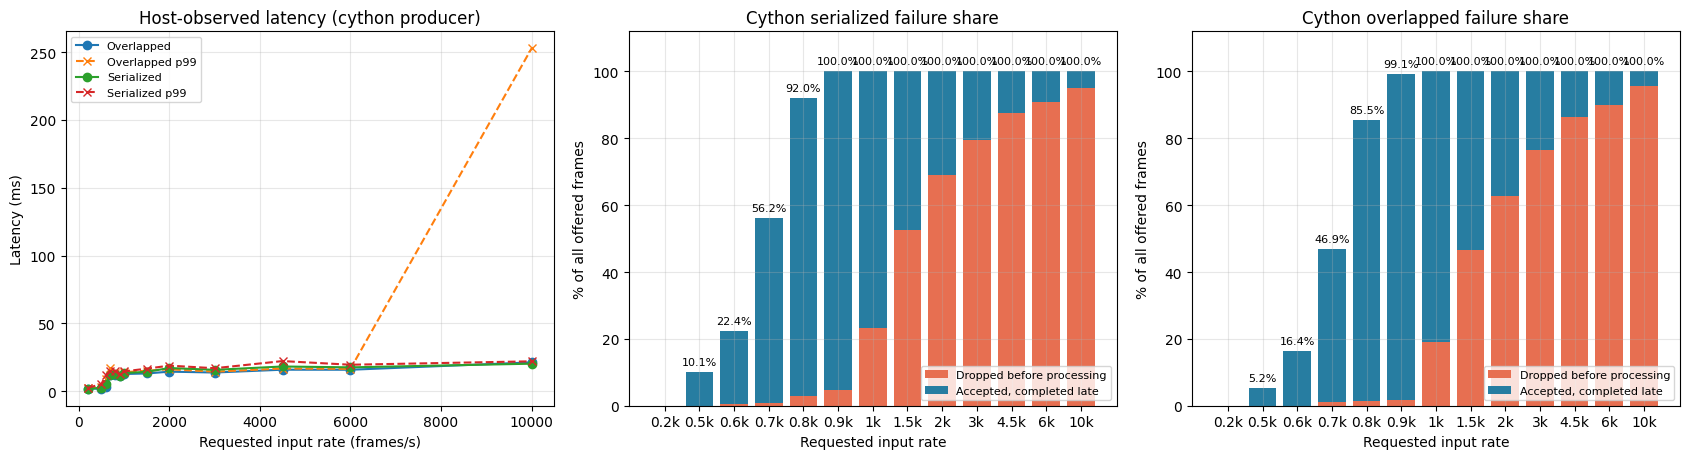

Saved: /content/realtime-beamforming-lab/results/exercise5-streaming-summary.json
Saved: /content/realtime-beamforming-lab/results/exercise5-streaming-power-maps.npz
Saved: /content/realtime-beamforming-lab/results/exercise5-streaming-latency.png


In [78]:
import matplotlib.pyplot as plt
import pandas as pd

summary_columns = [
    "producer_kind", "mode", "requested_rate_hz", "actual_producer_rate_hz", "offered_frames",
    "accepted_frames", "dropped_frames", "deadline_misses", "max_waiting_queue_depth",
    "latency_p50_ms", "latency_p95_ms", "latency_p99_ms", "latency_max_ms",
    "producer_lateness_p95_ms", "h2d_event_p50_ms",
    "gpu_beamform_power_p50_ms", "image_relative_rmse",
]
summary_rows = [{key: result.get(key) for key in summary_columns} for result in trial_results]
summary = pd.DataFrame(summary_rows)
summary["dropped_pct_offered"] = 100 * summary["dropped_frames"] / summary["offered_frames"]
summary["late_accepted_pct_offered"] = 100 * summary["deadline_misses"] / summary["offered_frames"]
summary["on_time_pct_offered"] = 100 - summary["dropped_pct_offered"] - summary["late_accepted_pct_offered"]
display(summary)

fig, axes = plt.subplots(1, 3, figsize=(17, 4.7))
for _mode, _group in summary.groupby("mode"):
    _group = _group.sort_values("requested_rate_hz")
    _label = _mode.capitalize()
    axes[0].plot(_group["requested_rate_hz"], _group["latency_p95_ms"], marker="o", label=_label)
    axes[0].plot(_group["requested_rate_hz"], _group["latency_p99_ms"], marker="x", linestyle="--", label=f"{_label} p99")
axes[0].set(title=f"Host-observed latency ({MAIN_PRODUCER_KIND} producer)", xlabel="Requested input rate (frames/s)", ylabel="Latency (ms)")
axes[0].legend(fontsize=8)

_failure_colors = {"dropped": "#e76f51", "late": "#277da1"}
for _axis, _mode in zip(axes[1:], ("serialized", "overlapped")):
    _group = summary[summary["mode"] == _mode].sort_values("requested_rate_hz")
    _x = np.arange(len(_group))
    _dropped = _group["dropped_pct_offered"].to_numpy()
    _late = _group["late_accepted_pct_offered"].to_numpy()
    _axis.bar(_x, _dropped, color=_failure_colors["dropped"], label="Dropped before processing")
    _axis.bar(_x, _late, bottom=_dropped, color=_failure_colors["late"], label="Accepted, completed late")
    _axis.set_xticks(_x, [f"{rate / 1000:g}k" for rate in _group["requested_rate_hz"]])
    _axis.set(ylim=(0, 112), title=f"Cython {_mode} failure share", xlabel="Requested input rate", ylabel="% of all offered frames")
    for _position, _total in zip(_x, _dropped + _late):
        if _total > 0:
            _axis.text(_position, _total + 1.5, f"{_total:.1f}%", ha="center", va="bottom", fontsize=8)
    _axis.legend(fontsize=8, loc="lower right")
for _axis in axes:
    _axis.grid(True, alpha=0.3)
fig.tight_layout()
latency_plot_path = RESULTS_DIR / "exercise5-streaming-latency.png"
fig.savefig(latency_plot_path, dpi=180, bbox_inches="tight")
plt.show()

serializable_results = []
power_maps = {}
for _index, _result in enumerate(trial_results):
    _serializable = {key: value for key, value in _result.items() if key not in {"power_map", "normalized_map"}}
    serializable_results.append(_serializable)
    if _result["normalized_map"] is not None:
        _key = f"{_result['mode']}_{_result['requested_rate_hz']}Hz"
        power_maps[_key] = _result["normalized_map"].astype(np.float32)

json_path = RESULTS_DIR / "exercise5-streaming-summary.json"
json_path.write_text(json.dumps({
    "runtime": runtime_metadata,
    "dataset": workload.data_provenance,
    "configuration": {
        "cycles_per_trial": CYCLES_PER_TRIAL,
        "producer_kind": MAIN_PRODUCER_KIND,
        "recorded_frame_count": frame_count,
        "replayed_frames_per_trial": replay_frames,
        "nominal_recorded_prf_hz": REPLAYED_PRF_HZ,
        "requested_rates_hz": list(INPUT_RATES_HZ),
        "queue_capacity": QUEUE_CAPACITY,
        "drop_policy": "drop newest when the waiting queue is full",
        "deadline": "scheduled arrival plus one requested input period",
        "nvtx_available": NVTX_AVAILABLE,
    },
    "results": serializable_results,
}, indent=2))
npz_path = RESULTS_DIR / "exercise5-streaming-power-maps.npz"
np.savez_compressed(npz_path, **power_maps)
print("Saved:", json_path)
print("Saved:", npz_path)
print("Saved:", latency_plot_path)


## The primary comparison uses Cython scheduling

The 13-rate serialized/overlapped sweep now uses the precompiled Cython producer. Its absolute `CLOCK_MONOTONIC` wait runs in a `nogil` section; creating each job and inserting it into Python's queue still needs the GIL. The batch sweep below keeps the producer fixed and changes the number of acquisitions passed to each beamform call.

At 10 kHz, the Cython main run accepted 411/8,192 serialized frames and 354/8,192 overlapped frames. Every accepted frame missed the 0.100 ms deadline, so both modes had 100% total failure share once drops and late completions are combined. The p95 host latency was 20.27 ms serialized and 21.25 ms overlapped. GPU beamform-plus-power medians were 1.56 and 1.48 ms respectively.

The overlapped 10 kHz main trial was anomalous: its measured producer rate was 9,052 frames/s and p95 producer lateness was 217 ms. The batch sweep includes a fresh B=1 control so this point can be checked alongside larger batches. The GPU event time is also far above the 0.1 ms arrival period; Cython addresses scheduling interference, not beamforming capacity.


### Selected timing rows from the Cython main sweep

The full per-rate table and plots above are the primary result. These rows show the low-load baseline and two saturated loads. Host latency runs from actual arrival through completion; GPU and H2D columns are CUDA event medians over accepted frames.

| Mode | Rate (Hz) | Accepted / offered | Dropped | Late | p95 host latency (ms) | H2D median (ms) | GPU median (ms) |
|---|---:|---:|---:|---:|---:|---:|---:|
| Serialized | 200 | 8,192 / 8,192 | 0 | 0 | 1.825 | 0.054 | 1.133 |
| Overlapped | 200 | 8,192 / 8,192 | 0 | 0 | 1.846 | 0.057 | 1.109 |
| Serialized | 6,000 | 750 / 8,192 | 7,442 | 750 | 17.571 | 0.061 | 1.423 |
| Overlapped | 6,000 | 831 / 8,192 | 7,361 | 831 | 15.805 | 0.060 | 1.315 |
| Serialized | 10,000 | 411 / 8,192 | 7,781 | 411 | 20.272 | 0.071 | 1.557 |
| Overlapped | 10,000 | 354 / 8,192 | 7,838 | 354 | 21.247 | 0.079 | 1.481 |

At 10 kHz, H2D is roughly 0.07–0.08 ms while GPU beamform-plus-power is 1.48–1.56 ms. Copy optimization may help, but the measured GPU work is the larger per-frame cost. The 10 kHz sample counts are small and the overlapped producer-lateness outlier is called out above.


## Follow-up: batch beamforming at 10 kHz

This experiment keeps the Cython producer and two-slot copy/compute pipeline, then varies how many accepted acquisitions are packed into each `mach.kernel.beamform` call. B=1 is a fresh same-session baseline against the main Cython overlapped result. The offline `run_ensemble` check first verifies that Mach's batch axis preserves the power-Doppler image while measuring resident-input kernel scaling; the scheduled replay then measures queue drops, batch deadlines, and end-to-end age.

For B consecutive input slots at requested rate f, the batch cadence is `B / f`. A batch is on time if its output is ready by the scheduled time of its last represented slot plus the represented span divided by f. Thus B=1 matches the original one-period deadline. A late batch counts each accepted member as late; missing arrivals remain drops. We also report the stricter per-frame one-period miss share and acquisition-to-output age, so the batch deadline does not conceal freshness costs. The scheduled replay uses a one-batch-cadence fill timeout and two batch slots; partial batches are zero-padded for the GPU call, while only real acquisitions contribute to the measured frame counts.



In [79]:
from dataclasses import dataclass
from queue import Empty, Full, Queue
from threading import Event, Thread
import time


@dataclass
class BatchStreamSlot:
    owner: object
    host: np.ndarray
    device: object
    copy_stream: object
    compute_stream: object
    copy_start: object
    copy_done: object
    compute_start: object
    compute_done: object
    jobs: list | None = None
    stage_start_ns: int = 0
    host_stage_ms: float = 0.0
    batch_fill_ms: float = 0.0
    batch_span_slots: int = 0


def make_batch_slot(batch_size: int, compute_stream) -> BatchStreamSlot:
    batch_shape = (frame_shape[0], frame_shape[1], batch_size)
    batch_bytes = frame_bytes * batch_size
    owner = cp.cuda.alloc_pinned_memory(batch_bytes)
    host = np.frombuffer(owner, dtype=np.complex64, count=int(np.prod(batch_shape))).reshape(batch_shape)
    device = cp.empty(batch_shape, dtype=cp.complex64)
    copy_stream = cp.cuda.Stream(non_blocking=True)
    return BatchStreamSlot(
        owner=owner,
        host=host,
        device=device,
        copy_stream=copy_stream,
        compute_stream=compute_stream,
        copy_start=cp.cuda.Event(),
        copy_done=cp.cuda.Event(),
        compute_start=cp.cuda.Event(),
        compute_done=cp.cuda.Event(),
    )


def run_batched_trial(batch_size: int, input_rate_hz: int = 10_000) -> dict:
    if batch_size < 1 or batch_size > frame_count:
        raise ValueError("batch_size must be between 1 and the recorded frame count")
    if input_rate_hz <= 0:
        raise ValueError("input_rate_hz must be positive")

    period_ns = int(round(1e9 / input_rate_hz))
    max_fill_wait_ns = batch_size * period_ns
    offered_count = replay_frames
    # One compute stream serializes accumulation into the shared power map;
    # independent copy streams still let the next H2D overlap current compute.
    compute_stream = cp.cuda.Stream(non_blocking=True)
    slots = [make_batch_slot(batch_size, compute_stream) for _ in range(2)]
    power_accumulator = cp.zeros(len(workload.scan_coords_m), dtype=cp.float32)
    cp.cuda.Device().synchronize()
    work_queue = Queue(maxsize=QUEUE_CAPACITY)
    producer_done = Event()
    arrivals, drops, producer_errors = [], [], []
    max_queue_depth = [0]
    completed, batch_records = [], []
    max_queue_depth_seen = 0
    trial_start_ns = time.perf_counter_ns()

    def produce():
        try:
            max_queue_depth[0] = int(_load_cython_scheduler().produce_arrivals(
                work_queue, arrivals, drops, offered_count, frame_count,
                trial_start_ns, period_ns,
            ))
        except BaseException as exc:
            producer_errors.append(exc)
        finally:
            producer_done.set()

    def submit(slot: BatchStreamSlot, jobs: list[dict]):
        stage_start_ns = time.perf_counter_ns()
        for index, job in enumerate(jobs):
            np.copyto(slot.host[:, :, index], channel_data[:, :, job["frame_index"]])
        if len(jobs) < batch_size:
            slot.host[:, :, len(jobs):] = 0
        slot.stage_start_ns = stage_start_ns
        slot.host_stage_ms = (time.perf_counter_ns() - stage_start_ns) / 1e6
        slot.jobs = jobs
        slot.batch_fill_ms = (jobs[-1]["arrived_ns"] - jobs[0]["arrived_ns"]) / 1e6
        slot.batch_span_slots = jobs[-1]["sequence"] - jobs[0]["sequence"] + 1

        with slot.copy_stream:
            slot.copy_start.record(slot.copy_stream)
            cp.cuda.runtime.memcpyAsync(
                int(slot.device.data.ptr),
                int(slot.host.ctypes.data),
                frame_bytes * batch_size,
                cp.cuda.runtime.memcpyHostToDevice,
                int(slot.copy_stream.ptr),
            )
            slot.copy_done.record(slot.copy_stream)

        slot.compute_stream.wait_event(slot.copy_done)
        with slot.compute_stream:
            slot.compute_start.record(slot.compute_stream)
            image = beamform(
                channel_data=slot.device,
                rx_coords_m=geometry.rx_coords_m,
                scan_coords_m=geometry.scan_coords_m,
                tx_wave_arrivals_s=geometry.tx_wave_arrivals_s,
                f_number=float(workload.params["fnumber"]),
                rx_start_s=float(workload.params["t0"]),
                sampling_freq_hz=float(workload.params["fs"]),
                sound_speed_m_s=float(workload.params["c"]),
                modulation_freq_hz=float(workload.params["fc"]),
                tukey_alpha=0.0,
            )
            batch_power = cp.sum(cp.abs(image) ** 2, axis=-1)
            cp.add(power_accumulator, batch_power, out=power_accumulator)
            slot.compute_done.record(slot.compute_stream)

    def finish(slot: BatchStreamSlot):
        completed_ns = time.perf_counter_ns()
        jobs = slot.jobs
        span_slots = slot.batch_span_slots
        deadline_ns = jobs[-1]["scheduled_ns"] + span_slots * period_ns
        batch_late = completed_ns > deadline_ns
        batch_records.append({
            "batch_size": len(jobs),
            "represented_slots": span_slots,
            "batch_fill_ms": slot.batch_fill_ms,
            "queue_wait_ms": (slot.stage_start_ns - jobs[0]["arrived_ns"]) / 1e6,
            "host_stage_ms": slot.host_stage_ms,
            "dispatch_to_done_ms": (completed_ns - slot.stage_start_ns) / 1e6,
            "ready_to_done_ms": (completed_ns - jobs[-1]["arrived_ns"]) / 1e6,
            "batch_deadline_ms": span_slots * period_ns / 1e6,
            "batch_late": batch_late,
            "h2d_ms": float(cp.cuda.get_elapsed_time(slot.copy_start, slot.copy_done)),
            "gpu_ms": float(cp.cuda.get_elapsed_time(slot.compute_start, slot.compute_done)),
        })
        for job in jobs:
            completed.append({
                **job,
                "completed_ns": completed_ns,
                "host_latency_ms": (completed_ns - job["arrived_ns"]) / 1e6,
                "scheduled_age_ms": (completed_ns - job["scheduled_ns"]) / 1e6,
                "queue_wait_ms": (slot.stage_start_ns - job["arrived_ns"]) / 1e6,
                "batch_deadline_miss": batch_late,
                "strict_frame_deadline_miss": completed_ns > job["scheduled_ns"] + period_ns,
            })
        slot.jobs = None

    _nvtx_pushed = False
    if NVTX_AVAILABLE:
        RangePush(f"exercise5/cython/overlapped/{input_rate_hz}Hz/batch{batch_size}")
        _nvtx_pushed = True
    producer = Thread(target=produce, name=f"exercise5-cython-batch{batch_size}-producer", daemon=True)
    pending: list[dict] = []
    producer.start()
    try:
        while True:
            progressed = False
            for slot in slots:
                if slot.jobs is not None and slot.compute_done.done:
                    finish(slot)
                    progressed = True

            max_queue_depth_seen = max(max_queue_depth_seen, max_queue_depth[0], work_queue.qsize())
            free_slot = next((slot for slot in slots if slot.jobs is None), None)
            if free_slot is not None:
                while len(pending) < batch_size:
                    try:
                        pending.append(work_queue.get_nowait())
                        progressed = True
                    except Empty:
                        break
                flush_partial = bool(pending) and (
                    producer_done.is_set() and work_queue.empty()
                    or time.perf_counter_ns() - pending[0]["arrived_ns"] >= max_fill_wait_ns
                )
                if len(pending) == batch_size or flush_partial:
                    submit(free_slot, pending.copy())
                    pending.clear()
                    progressed = True

            if producer_done.is_set() and work_queue.empty() and not pending and all(slot.jobs is None for slot in slots):
                break
            if not progressed:
                time.sleep(POLL_INTERVAL_S)
    finally:
        producer.join()
        for slot in slots:
            if slot.jobs is not None:
                slot.compute_done.synchronize()
                finish(slot)
        if _nvtx_pushed:
            RangePop()

    if producer_errors:
        raise RuntimeError("Cython batch producer failed") from producer_errors[0]
    cp.cuda.Device().synchronize()
    power_map = cp.asnumpy(power_accumulator).reshape(len(workload.x_m), len(workload.z_m))
    trial_end_ns = time.perf_counter_ns()

    accepted = len(completed)
    batch_late_frames = sum(r["batch_deadline_miss"] for r in completed)
    strict_late_frames = sum(r["strict_frame_deadline_miss"] for r in completed)
    producer_lateness_ms = np.asarray([(r["arrived_ns"] - r["scheduled_ns"]) / 1e6 for r in arrivals])
    host_latency_ms = np.asarray([r["host_latency_ms"] for r in completed])
    scheduled_age_ms = np.asarray([r["scheduled_age_ms"] for r in completed])
    batch_gpu_ms = np.asarray([r["gpu_ms"] for r in batch_records])
    batch_h2d_ms = np.asarray([r["h2d_ms"] for r in batch_records])
    batch_fill_ms = np.asarray([r["batch_fill_ms"] for r in batch_records])
    batch_stage_ms = np.asarray([r["host_stage_ms"] for r in batch_records])
    batch_wall_ms = np.asarray([r["dispatch_to_done_ms"] for r in batch_records])
    batch_ready_ms = np.asarray([r["ready_to_done_ms"] for r in batch_records])
    actual_rate_hz = (
        (len(arrivals) - 1) * 1e9 / (arrivals[-1]["arrived_ns"] - arrivals[0]["arrived_ns"])
        if len(arrivals) > 1 and arrivals[-1]["arrived_ns"] > arrivals[0]["arrived_ns"] else 0.0
    )
    image_relative_rmse = None
    if accepted == offered_count and not drops:
        normalized_map = power_map / CYCLES_PER_TRIAL
        image_relative_rmse = float(
            np.sqrt(np.mean((normalized_map - reference) ** 2))
            / max(np.sqrt(np.mean(reference ** 2)), np.finfo(float).eps)
        )

    return {
        "producer_kind": "cython",
        "mode": "overlapped",
        "batch_size_target": batch_size,
        "requested_rate_hz": input_rate_hz,
        "actual_producer_rate_hz": float(actual_rate_hz),
        "offered_frames": offered_count,
        "accepted_frames": accepted,
        "dropped_frames": len(drops),
        "batch_deadline_miss_frames": int(batch_late_frames),
        "strict_frame_deadline_miss_frames": int(strict_late_frames),
        "batch_deadline_failure_share_pct": 100 * (len(drops) + batch_late_frames) / offered_count,
        "strict_frame_failure_share_pct": 100 * (len(drops) + strict_late_frames) / offered_count,
        "max_waiting_queue_depth": int(max_queue_depth_seen),
        "trial_wall_s": (trial_end_ns - trial_start_ns) / 1e9,
        "completed_frames_per_s": accepted / ((trial_end_ns - trial_start_ns) / 1e9),
        "latency_p50_ms": float(np.percentile(host_latency_ms, 50)) if accepted else None,
        "latency_p95_ms": float(np.percentile(host_latency_ms, 95)) if accepted else None,
        "scheduled_age_p95_ms": float(np.percentile(scheduled_age_ms, 95)) if accepted else None,
        "producer_lateness_p95_ms": float(np.percentile(producer_lateness_ms, 95)) if len(arrivals) else None,
        "batch_size_mean": float(np.mean([b["batch_size"] for b in batch_records])) if batch_records else None,
        "batch_fill_p50_ms": float(np.percentile(batch_fill_ms, 50)) if len(batch_fill_ms) else None,
        "host_stage_p50_ms_per_batch": float(np.percentile(batch_stage_ms, 50)) if len(batch_stage_ms) else None,
        "batch_wall_p50_ms": float(np.percentile(batch_wall_ms, 50)) if len(batch_wall_ms) else None,
        "ready_to_done_p50_ms": float(np.percentile(batch_ready_ms, 50)) if len(batch_ready_ms) else None,
        "batch_deadline_p50_ms": float(np.percentile([b["batch_deadline_ms"] for b in batch_records], 50)) if batch_records else None,
        "h2d_event_p50_ms_per_batch": float(np.percentile(batch_h2d_ms, 50)) if len(batch_h2d_ms) else None,
        "gpu_event_p50_ms_per_batch": float(np.percentile(batch_gpu_ms, 50)) if len(batch_gpu_ms) else None,
        "image_relative_rmse": image_relative_rmse,
        "power_map": power_map,
        "batch_records": batch_records,
        "frame_records": completed,
        "drops": drops,
    }


Offline full-ensemble batch check (resident input; no arrival queue):
B=1: GPU=29.415 ms, wall=38.839 ms, 824 frames/s, RMSE=0.00e+00
B=2: GPU=20.506 ms, wall=26.616 ms, 1202 frames/s, RMSE=1.18e-07
B=4: GPU=13.609 ms, wall=18.062 ms, 1772 frames/s, RMSE=1.16e-07
B=8: GPU=5.625 ms, wall=8.903 ms, 3594 frames/s, RMSE=1.14e-07
B=16: GPU=3.027 ms, wall=5.841 ms, 5479 frames/s, RMSE=1.11e-07

Cython overlapped replay at 10,000 Hz (8,192 offered frames each):
B=1: accepted=503, dropped=7,689, batch-late=503, failure=100.0%, throughput=607 frames/s, p95 age=17.32 ms
B=2: accepted=708, dropped=7,484, batch-late=708, failure=100.0%, throughput=856 frames/s, p95 age=12.81 ms
B=4: accepted=880, dropped=7,312, batch-late=880, failure=100.0%, throughput=1063 frames/s, p95 age=13.48 ms
B=8: accepted=1,208, dropped=6,984, batch-late=1,208, failure=100.0%, throughput=1463 frames/s, p95 age=12.59 ms
B=16: accepted=952, dropped=7,240, batch-late=952, failure=100.0%, throughput=1151 frames/s, p95 age=16

B,GPU ms / ensemble,Wall ms,Frames/s,RMSE vs B=1
1,29.415,38.839,824,0.00e+00
2,20.506,26.616,1202,1.18e-07
4,13.609,18.062,1772,1.16e-07
8,5.625,8.903,3594,1.14e-07
16,3.027,5.841,5479,1.11e-07


B,Accepted,Dropped,Batch-late,Failure %,Accepted frames/s,p95 age (ms),GPU ms/batch,Budget (ms)
1,503,7689,503,100.0,607,17.32,1.248,0.10
2,708,7484,708,100.0,856,12.81,1.443,0.20
4,880,7312,880,100.0,1063,13.48,2.060,0.40
8,1208,6984,1208,100.0,1463,12.59,1.812,0.80
16,952,7240,952,100.0,1151,16.02,1.782,1.60


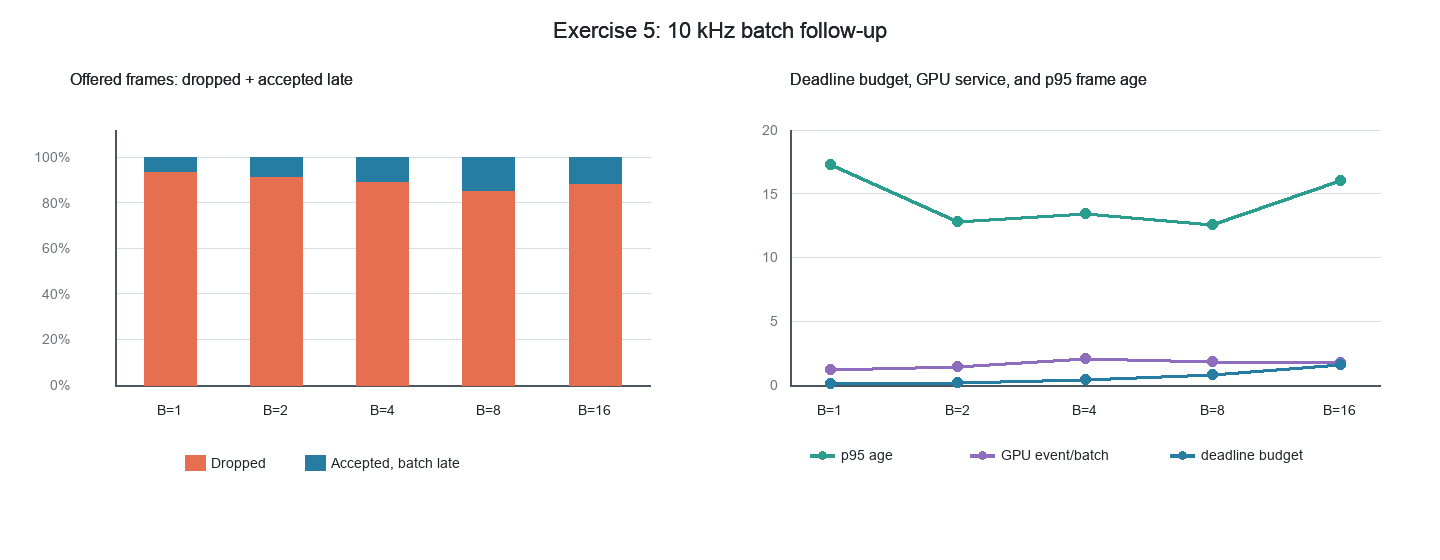

In [80]:
BATCH_SIZES = (1, 2, 4, 8, 16)
BATCH_TEST_RATE_HZ = 10_000
BATCH_REPEATS = 3

# First check batch-axis image agreement and resident-input kernel scaling.
# The first call for each size is a warmup; timings below are medians of repeats.
offline_batch_rows = []
for _batch_size in BATCH_SIZES:
    run_ensemble(workload, geometry, batch_size=_batch_size)
    _offline_runs = [run_ensemble(workload, geometry, batch_size=_batch_size) for _ in range(BATCH_REPEATS)]
    _offline_image = _offline_runs[-1]["power_doppler"]
    _offline_diff = _offline_image - reference
    offline_batch_rows.append({
        "batch_size": _batch_size,
        "beamform_device_ms": float(np.median([r["beamform_device_ms"] for r in _offline_runs])),
        "beamform_host_call_ms": float(np.median([r["beamform_host_call_ms"] for r in _offline_runs])),
        "one_time_upload_ms": float(np.median([r["input_upload_ms"] for r in _offline_runs])),
        "ensemble_wall_ms": float(np.median([r["run_wall_ms"] for r in _offline_runs])),
        "frames_per_second_wall": frame_count * 1_000 / float(np.median([r["run_wall_ms"] for r in _offline_runs])),
        "image_relative_rmse_vs_B1": float(
            np.sqrt(np.mean(_offline_diff ** 2))
            / max(np.sqrt(np.mean(reference ** 2)), np.finfo(float).eps)
        ),
    })
offline_batch_summary = pd.DataFrame(offline_batch_rows)
print("Offline full-ensemble batch check (resident input; no arrival queue):")
display(offline_batch_summary)

# Then test scheduled arrivals and the batch-cadence deadline at 10 kHz.
batch_trial_results = []
for _batch_size in BATCH_SIZES:
    print(f"Running Cython overlapped replay at {BATCH_TEST_RATE_HZ:,} Hz, batch={_batch_size} ...")
    _result = run_batched_trial(_batch_size, input_rate_hz=BATCH_TEST_RATE_HZ)
    batch_trial_results.append(_result)
    print(
        f"  accepted={_result['accepted_frames']:,}, dropped={_result['dropped_frames']:,}, "
        f"batch-late={_result['batch_deadline_miss_frames']:,}, "
        f"batch failure={_result['batch_deadline_failure_share_pct']:.1f}%, "
        f"completed={_result['completed_frames_per_s']:.0f} frames/s, "
        f"p95 age={_result['scheduled_age_p95_ms']:.3f} ms"
    )

batch_summary_rows = []
for _result in batch_trial_results:
    batch_summary_rows.append({key: value for key, value in _result.items()
                               if key not in {"power_map", "batch_records", "frame_records", "drops"}})
batch_summary = pd.DataFrame(batch_summary_rows)
batch_display_columns = [
    "batch_size_target", "accepted_frames", "dropped_frames",
    "batch_deadline_miss_frames", "batch_deadline_failure_share_pct",
    "strict_frame_failure_share_pct", "completed_frames_per_s",
    "scheduled_age_p95_ms", "gpu_event_p50_ms_per_batch", "batch_deadline_p50_ms",
]
batch_display = batch_summary[batch_display_columns].rename(columns={
    "batch_size_target": "B", "accepted_frames": "Accepted", "dropped_frames": "Dropped",
    "batch_deadline_miss_frames": "Batch-late", "batch_deadline_failure_share_pct": "Batch failure (%)",
    "strict_frame_failure_share_pct": "Strict failure (%)", "completed_frames_per_s": "Accepted frames/s",
    "scheduled_age_p95_ms": "p95 age (ms)", "gpu_event_p50_ms_per_batch": "GPU ms/batch",
    "batch_deadline_p50_ms": "Batch budget (ms)",
})
display(batch_display)

offered = batch_summary["offered_frames"].to_numpy()
dropped_pct = 100 * batch_summary["dropped_frames"].to_numpy() / offered
late_pct = 100 * batch_summary["batch_deadline_miss_frames"].to_numpy() / offered
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
_x = np.arange(len(BATCH_SIZES))
axes[0].bar(_x, dropped_pct, color="#e76f51", label="Dropped")
axes[0].bar(_x, late_pct, bottom=dropped_pct, color="#277da1", label="Accepted, batch late")
axes[0].set_xticks(_x, [str(b) for b in BATCH_SIZES])
axes[0].set(xlabel="Acquisitions per beamform call", ylabel="% of offered frames",
            title="10 kHz batch-aware failure share", ylim=(0, 112))
axes[0].legend()
axes[0].grid(True, axis="y", alpha=0.3)
axes[1].plot(BATCH_SIZES, batch_summary["scheduled_age_p95_ms"], marker="o", label="p95 acquisition-to-output age")
axes[1].plot(BATCH_SIZES, batch_summary["batch_deadline_p50_ms"], marker="s", label="median batch deadline budget")
axes[1].plot(BATCH_SIZES, batch_summary["gpu_event_p50_ms_per_batch"], marker="^", label="GPU event median per batch")
axes[1].set(xlabel="Target acquisitions per beamform call", ylabel="Time (ms)",
            title="Batch cadence and frame age")
axes[1].grid(True, alpha=0.3)
axes[1].legend(fontsize=8)
fig.tight_layout()
batch_plot_path = RESULTS_DIR / "exercise5-batching-10khz.png"
fig.savefig(batch_plot_path, dpi=180, bbox_inches="tight")
plt.show()

batch_json_path = RESULTS_DIR / "exercise5-batching-10khz.json"
batch_json_path.write_text(json.dumps({
    "runtime": runtime_metadata,
    "dataset": workload.data_provenance,
    "configuration": {
        "requested_rate_hz": BATCH_TEST_RATE_HZ,
        "batch_sizes": list(BATCH_SIZES),
        "producer_kind": "cython",
        "pipeline_mode": "overlapped",
        "queue_capacity_frames": QUEUE_CAPACITY,
        "max_fill_wait_periods": 1,
        "batch_deadline": "scheduled last represented slot plus represented_slots / requested_rate",
        "strict_per_frame_deadline": "scheduled arrival plus one input period",
        "offline_batch_repeats": BATCH_REPEATS,
    },
    "offline_batch_results": offline_batch_rows,
    "streaming_results": [
        {key: value for key, value in result.items()
         if key not in {"power_map", "batch_records", "frame_records", "drops"}}
        for result in batch_trial_results
    ],
}, indent=2))
complete_batch_maps = {
    f"batch_{r['batch_size_target']}": r["power_map"].astype(np.float32)
    for r in batch_trial_results if r["image_relative_rmse"] is not None
}
print("Saved:", batch_json_path)
if complete_batch_maps:
    batch_npz_path = RESULTS_DIR / "exercise5-batching-10khz-power-maps.npz"
    np.savez_compressed(batch_npz_path, **complete_batch_maps)
    print("Saved:", batch_npz_path)
else:
    print("No complete streaming power-map archive: no trial accepted the full replay.")
print("Saved:", batch_plot_path)


## Reading the batch results

**The Mach batch axis preserves the image and improves offline throughput.** The relative RMSE against B=1 stays at or below `1.18e-7`. With the 32-frame ensemble already resident, wall throughput rises from about 824 frames/s at B=1 to 5,479 frames/s at B=16; GPU beamform time for the ensemble falls from 29.4 ms to 3.03 ms. This isolates the benefit of packing acquisitions into fewer beamform calls.

**Batching improves, but does not meet the 10 kHz streaming deadline.** The fresh B=1 control accepts 503 frames (607 accepted frames/s); B=8 is best at about 1,463 accepted frames/s (2.4× B=1), then B=16 falls to about 1,151 frames/s. At every size, all 8,192 offered frames are accounted for as dropped or late. Every accepted frame misses both the batch-aware deadline and the stricter one-period deadline. For B=8 the budget is 0.8 ms while the median GPU event is 1.81 ms; for B=16 the budget is 1.6 ms and the median GPU event is 1.78 ms.

**The freshness cost remains large.** Even at B=8, p95 scheduled acquisition-to-output age is 12.59 ms. Increasing B lowers drops through B=8 but does not turn this workload into a 10 kHz deadline-satisfying pipeline; B=16 reduces throughput and raises p95 age to 16.02 ms. The new B=1 control also differs from the main sweep (503 accepted versus 354), so treat exact counts as one-run observations; both trials still show 100% failure share.

**Streaming image accuracy is unavailable.** None of the scheduled trials accepts the complete 8,192-frame replay, so an ensemble image RMSE cannot be reported. The offline check supplies the batch-axis accuracy result. The notebook only archives a streaming power-map NPZ when a trial completes the full replay; the JSON summary and plot are saved under `results/`.


## Nsight Systems check and interpretation

This notebook adds one NVTX range per mode/rate trial when CuPy's NVTX wrapper is available. Capture a short run from the connected Colab terminal after checking the installed `nsys` version and notebook-kernel process. Save the `.nsys-rep` under `artifacts/` and use the timeline to confirm whether H2D copies overlap beamforming kernels. CUDA event timings alone cannot establish overlap.

**Interpretations and takeaways:**

- The Cython 200 Hz baseline completed all 8,192 frames on time in both modes. At 500 Hz both modes had deadline misses but no drops. At 600 Hz the serialized run also dropped 30 frames, while overlapped dropped none; drops first appeared at 700 Hz in the overlapped run. By 1 kHz, no accepted frame completes within one input period.
- At 10 kHz the input period is 0.100 ms, versus 1.48–1.56 ms for the GPU beamform-plus-power event. Only 411 serialized and 354 overlapped frames were accepted; all accepted frames were late, giving 100% total failure share. The bounded queue drops most offered arrivals. Increasing its capacity would hold more stale work without raising sustained service rate.
- The main sweep uses Cython throughout. Its overlapped 10 kHz result had unusually high producer lateness; the B=1 batch replay and larger batches provide a same-session check of that rate.
- H2D takes about 0.05–0.08 ms in the selected rows, much less than GPU work at high rates. Check the Nsight Systems timeline before claiming that the overlapped path achieves copy/compute overlap.

This is repeated replay of stored PyMUST data, not a live scanner capture. The main and batched comparisons use the same Cython arrival scheduler and dataset; the batch experiment changes how many acquisitions each beamform call processes.
